# Thermochemistry of Water

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4v2/blob/main/temp/05-thermochemistry.ipynb)
:::


In [1]:
####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path
import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Style sheets and helper functions from the book's GitHub repository
if IN_COLAB:
    if not Path("styles/tufte.mplstyle").exists():
        !wget -q -N -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/tufte.mplstyle
        !wget -q -N https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/psi4_helpers.py
    plt.style.use("styles/tufte.mplstyle")
    nproc = 2          # Colab gives you 2 cores
else:
    sys.path.insert(0, "..")                    # psi4_helpers.py is one folder up
    plt.style.use("../styles/tufte.mplstyle")
    nproc = 4          # house limit: 4 threads

import psi4_helpers as ph

# All Psi4 .out and .log files go into the output folder
output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

# Resources: house limits are 4 threads and 4 GB
psi4.set_num_threads(nproc)
_ = psi4.set_memory("2 GB")


  Threads set to 4 by Python driver.



  Memory set to   1.863 GiB by Python driver.


The energy from `psi4.energy()` is the **electronic energy** of motionless nuclei at the bottom of the potential well. Real molecules vibrate even at 0 K, and at room temperature they also move and rotate. A frequency calculation gives us everything needed to turn the electronic energy into the quantities chemists use: **enthalpy** $H$, **entropy** $S$ and **Gibbs free energy** $G$.

## What You Will Learn
- What the **zero-point vibrational energy** (ZPVE) is and how large it is.
- How *Psi4* builds $H$, $S$ and $G$ from translations, rotations and vibrations.
- How to recalculate the thermochemistry at other **temperatures** without repeating the expensive Hessian.
- What assumptions (ideal gas, rigid rotor, harmonic oscillator) lie behind the numbers.

In [2]:
psi4.set_output_file("output/05-thermochemistry.out", False);
psi4.set_options({"basis": "6-31g*", "scf_type": "df"})

h2kJ = psi4.constants.hartree2kJmol

## 1. Optimize and Calculate Frequencies

We use B3LYP/6-31G*, a common choice for organic thermochemistry: it is cheap and its frequencies need only a small scale factor.

```{note} Psi4 settings for thermochemistry
:class: dropdown
`t` (default 298.15 K)
: The temperature used for the thermal corrections.

`p` (default 101325 Pa = 1 atm)
: The pressure of the ideal-gas **standard state**. Modern tables use 1 bar (`100000`). For water the difference in $G$ is only 0.03 kJ/mol, but it matters when you compare with tabulated data.

`rotational_symmetry_number` (set automatically)
: The number of ways the molecule can be rotated into an identical orientation, $\sigma$. Water has $\sigma = 2$ (the $C_2$ axis). It lowers the rotational entropy by $R\ln\sigma$. *Psi4* works it out from the full point group.

*Alternative methods:* `hf/6-31g*` (cheaper; frequencies too high, so ZPVE too large), `wb97x-d/def2-tzvp` (more accurate). For high-accuracy energies a common recipe is a CCSD(T) energy plus B3LYP thermal corrections.
```

In [3]:
water = psi4.geometry("""
0 1
O
H 1 0.96
H 1 0.96 2 104.5
""")

psi4.optimize("b3lyp", molecule=water)
E_elec, wfn = psi4.frequency("b3lyp", molecule=water, return_wfn=True)
print("Frequencies (cm-1):", ", ".join(f"{f:.1f}" for f in wfn.frequencies().np))

Optimizer: Optimization complete!


Frequencies (cm-1): 1713.2, 3727.7, 3849.4


## 2. The Thermochemistry Table

*Psi4* stores the results as **PSI variables**. The *corrections* are added to the electronic energy to give the totals.

In [4]:
T = psi4.core.get_option("THERMO", "T")

thermo = pd.DataFrame([
    ("Electronic energy E(elec)",   E_elec,                                   np.nan),
    ("Zero-point energy (ZPVE)",    psi4.variable("ZPVE"),                    psi4.variable("ZPVE") * h2kJ),
    ("E(elec) + ZPVE  (0 K)",       psi4.variable("ZERO K ENTHALPY"),         np.nan),
    ("Thermal energy correction",   psi4.variable("THERMAL ENERGY CORRECTION"), psi4.variable("THERMAL ENERGY CORRECTION") * h2kJ),
    ("Enthalpy correction",         psi4.variable("ENTHALPY CORRECTION"),     psi4.variable("ENTHALPY CORRECTION") * h2kJ),
    ("Enthalpy H",                  psi4.variable("ENTHALPY"),                np.nan),
    ("Gibbs free energy correction",psi4.variable("GIBBS FREE ENERGY CORRECTION"), psi4.variable("GIBBS FREE ENERGY CORRECTION") * h2kJ),
    ("Gibbs free energy G",         psi4.variable("GIBBS FREE ENERGY"),       np.nan),
], columns=["quantity", "hartree", "kJ/mol"])

S = (psi4.variable("ENTHALPY") - psi4.variable("GIBBS FREE ENERGY")) / T * h2kJ * 1000   # J/(mol K)
print(f"T = {T} K;  entropy S = {S:.1f} J/(mol K)   (experiment for water vapour: 188.8 J/(mol K))")
thermo.round({"hartree": 6, "kJ/mol": 2})

T = 298.15 K;  entropy S = 188.9 J/(mol K)   (experiment for water vapour: 188.8 J/(mol K))


,quantity,hartree,kJ/mol
0,Electronic energy E(elec),-76.408955,NaN
1,Zero-point energy (ZPVE),0.021165,55.57
2,E(elec) + ZPVE (0 K),-76.387790,NaN
3,Thermal energy correction,0.023999,63.01
4,Enthalpy correction,0.024944,65.49
5,Enthalpy H,-76.384012,NaN
6,Gibbs free energy correction,0.003498,9.18
7,Gibbs free energy G,-76.405458,NaN


Some things to notice:

- The **ZPVE** is about 55 kJ/mol. That is half of $h\nu$ summed over the three modes, and it is far larger than the energy of a hydrogen bond. It matters whenever bonds to hydrogen are made or broken (see the *Isotope Effects* and *Hydrogen Bonding* notebooks).
- The **enthalpy correction** adds the thermal energy of translation ($\tfrac{3}{2}RT$), rotation ($\tfrac{3}{2}RT$ for a non-linear molecule) and vibration, plus $PV = RT$.
- The **Gibbs free energy correction** is much smaller than the enthalpy correction because of the $-TS$ term.
- The calculated **entropy** is very close to the experimental value. Entropy comes almost entirely from translation and rotation, which depend only on the mass and the structure.

The `output/05-thermochemistry.out` file breaks every quantity down into translational, rotational, vibrational and electronic parts. Search it for `Thermochemistry Components`.

In [5]:
ph.search_file("output/05-thermochemistry.out", "Total S")

  6114:   Total S                                   45.137 [cal/(mol K)]      188.853 [J/(mol K)]       0.07193020 [mEh/K]


## 3. Other Temperatures without a New Hessian

The Hessian is the expensive part. Once we have it, `psi4.driver.vibanal_wfn()` repeats only the cheap analysis. We change the `t` option and call it for a range of temperatures.

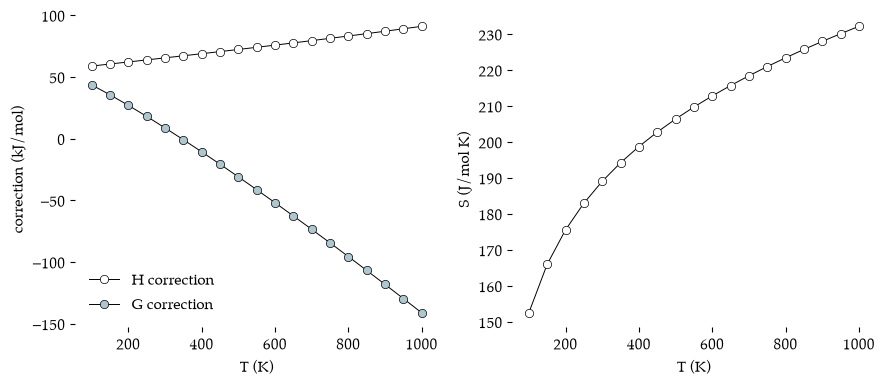

In [6]:
temperatures = np.arange(100, 1001, 50)
rows = []
for temp in temperatures:
    psi4.set_options({"t": float(temp)})
    psi4.driver.vibanal_wfn(wfn)
    H_corr = psi4.variable("ENTHALPY CORRECTION") * h2kJ
    G_corr = psi4.variable("GIBBS FREE ENERGY CORRECTION") * h2kJ
    rows.append({"T (K)": temp, "H corr (kJ/mol)": H_corr, "G corr (kJ/mol)": G_corr,
                 "S (J/mol K)": (H_corr - G_corr) / temp * 1000})

psi4.set_options({"t": 298.15})       # restore the default
temp_table = pd.DataFrame(rows)

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(9,4))
axs[0].plot(temp_table["T (K)"], temp_table["H corr (kJ/mol)"], color="black", linewidth=0.7, marker="o",
            markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5, label="H correction")
axs[0].plot(temp_table["T (K)"], temp_table["G corr (kJ/mol)"], color="black", linewidth=0.7, marker="o",
            markerfacecolor="#AEC6CF", markeredgecolor="black", markeredgewidth=0.5, label="G correction")
axs[0].set_xlabel("T (K)")
axs[0].set_ylabel("correction (kJ/mol)")
axs[0].legend()

axs[1].plot(temp_table["T (K)"], temp_table["S (J/mol K)"], color="black", linewidth=0.7, marker="o",
            markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5)
axs[1].set_xlabel("T (K)")
axs[1].set_ylabel("S (J/mol K)")
plt.tight_layout()
plt.show()

The enthalpy correction rises slowly with temperature, while $G$ falls steeply because of the growing $-TS$ term. This is why entropy-driven processes (such as dissociation into more molecules) win at high temperature.

```{important} The assumptions behind these numbers
- **Ideal gas**: no interactions between molecules. These are gas-phase values.
- **Rigid rotor**: the structure does not change as the molecule rotates.
- **Harmonic oscillator**: each vibration is a perfect spring. Low-frequency, floppy motions (such as the intermolecular modes of the water dimer) are poorly described, and they dominate the vibrational entropy. Treat entropies of weakly bound complexes with caution.
```

## Summary
- A frequency calculation gives ZPVE, $H$, $S$ and $G$ through the PSI variables `ZPVE`, `ENTHALPY`, `GIBBS FREE ENERGY` and their corrections.
- ZPVE for water is about 55 kJ/mol, large compared with many reaction energies.
- `psi4.driver.vibanal_wfn()` recalculates thermochemistry at a new temperature (or for new isotopic masses) from an existing Hessian.
- Compare with tables at the same standard state (1 atm or 1 bar).